# Hi!ckathon #7 — Task 1: Parliamentary Emotionality Prediction (Valence & Arousal)
### Deep Dive into the Task, the Valence–Arousal Index, Exploratory Analysis (`sample_x_test.csv`), and Action Plan

---

## 1. Challenge Overview (from `Opening_Hi!ckathon7.pdf`)

- **Theme:** *AI & Democracy — From Parliamentary Speeches to Democratic Insights* (guided by Prof. Yann Algan, HEC Paris).
- **Core Thesis:** Across Western democracies (France, US, UK, Italy, Germany), political discourse has shifted from aggregating interests to expressing **raw emotion** — particularly **anger** and **polarization** (French National Assembly emotional speeches rose from **27% → 40%** and polarization **×6** since 2007).
- **Task 1 — Predictive Modeling (Deliverable 1):**
  - **Objective:** Predict the emotionality of parliamentary speeches using **Valence** and **Arousal** as target indices (`valence_chunks_weighted_mean`, `arousal_chunks_weighted_mean` as defined in `y_test_zero.csv`).
  - **Leaderboard & Constraints:**
    - Submit predictions in `.csv` format matching `y_test_zero.csv` (**372,812 rows × 3 columns**: `id`, `valence_chunks_weighted_mean`, `arousal_chunks_weighted_mean`).
    - **Strict limit: maximum 10 leaderboard submissions** before **Sunday, Nov 29 at 4:00 PM**.
    - **Best Score Award** (TotalEnergies) is decided by the leaderboard on Sunday at 4:00 PM.
  - **Mandatory Live Code Assessment (Sunday 4:00–5:00 PM — Disqualification Risk):**
    - Submit clean, modular `.ipynb` or `.py` code (functions/classes, docstrings, comments, markdown explanations).
    - You **must run preprocessing + inference live on 10,000 rows** in front of Data Science coaches.
  - **Dataset Landscape:**
    - `x_train_final.csv`: **869,896 speeches** (`id` `0`–`869,895`), **exact 25% balance** across 4 chambers (`217,474` each: `assemblee`, `senat`, `uk_commons`, `us_congress`), spanning `1988-11-22` → `2026-06-17`.
    - `x_test_final.csv`: **372,812 speeches** (`id` `869,896`–`1,242,707`), **exact 25% balance** (`93,203` each), spanning the **exact same date range** (`1988-11-22` → `2026-06-17`) — a **70/30 stratified split** rather than a future-only holdout.
    - `sample_x_test.csv`: **10,000 speeches** × **218 columns** — ideal for rapid EDA, prototyping, and live-assessment timing. *(Important quirk discovered in our audit: its IDs range from `31` to `869,721`, meaning it is a 10,000-row sample drawn from `x_train_final.csv`, not `x_test_final.csv`!)*
    - `x_Italia.csv`: Cross-parliament comparison dataset (`216` columns, without `id`/`source`) for Task 2 & International Prize.
    - **Immediate Action Item #0:** Verify & download the training label file (`y_train_final.csv` / `y_train.csv`) and the exact leaderboard metric (RMSE / MAE / R² / Pearson) from **HFactory / Google Drive**, since only `y_test_zero.csv` is currently present in `dataset/`.

## 2. Understanding the Target Index: What Are Valence & Arousal?

### 2.1 Russell's Circumplex Model of Affect (1980)

Rather than collapsing emotions into discrete buckets ("angry", "happy", "sad"), affective science represents emotional states in a continuous **2D Valence–Arousal space** (often extended to 3D with **Dominance**, forming the **VAD** framework):

| Dimension | Psychological Meaning | Low Values (near 0) | Neutral (~0.5) | High Values (near 1) | Parliamentary Examples |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Valence ($V$)** | **Polarity / Pleasantness** (negative ↔ positive hedonic tone) | Hostility, anger, crisis, grief, accusation, failure | Procedural, factual, technical amendment | Praise, gratitude, hope, consensus, celebration | *"Ce texte est un scandale inacceptable"* (Low $V$) vs. *"I warmly congratulate my hon. Friend"* (High $V$) |
| **Arousal ($A$)** | **Activation / Intensity** (calm/subdued ↔ agitated/energetic) | Calm, routine, bored, resigned, somber | Measured debate, standard policy argument | Urgent, heated, furious, passionate, triumphant | *"L'article 13 est adopté."* (Low $A$) vs. *"Stop this disaster right now!"* (High $A$) |
| **Dominance ($D$)** *(feature only)* | **Control / Assertiveness** (submissive ↔ dominant) | Helplessness, fear, deference | Balanced tone | Commanding, forceful, uncompromising | Provided in NRC VAD lexicon features (`nrc_D_*`) — a valuable predictor! |

### 2.2 The Four Affective Quadrants in Parliamentary Discourse

Combining **Valence ($V$)** and **Arousal ($A$)** partitions every speech into four interpretable regimes:

1. **Low Valence + High Arousal → Anger / Outrage / Alarm**
   - *The exact "Age of Anger" / "Fièvre parlementaire" quadrant highlighted in Prof. Yann Algan's opening talk.* High-energy attacks, accusations, urgent warnings, heckling.
2. **Low Valence + Low Arousal → Sadness / Resignation / Somberness**
   - Tributes, mourning, solemn concern, bleak economic assessments delivered calmly.
3. **High Valence + High Arousal → Enthusiasm / Triumph / Pride**
   - Rallying speeches, celebrations of legislative victories, passionate calls for hope.
4. **High Valence + Low Arousal → Calm / Courtesy / Procedural Consensus**
   - Formal thanks, routine legislative procedures, polite bipartisan agreement.

### 2.3 Why Are the Targets Named `valence_chunks_weighted_mean` and `arousal_chunks_weighted_mean`?

Look closely at the exact target column names in `y_test_zero.csv`:
- `valence_chunks_weighted_mean`
- `arousal_chunks_weighted_mean`

Parliamentary speeches range from **1-word floor interjections** to **multi-thousand-word debates**, far exceeding standard Transformer context windows (e.g., 512 tokens). The ground-truth target was therefore constructed by:
1. Splitting each speech into **chunks** (segments/windows of text),
2. Scoring each chunk $k \in \{1, \dots, K\}$ for contextual Valence $v_k$ and Arousal $a_k$,
3. Computing a **length-weighted average** across chunks:

$$y_{\text{valence}} = \frac{\sum_{k=1}^{K} w_k \, v_k}{\sum_{k=1}^{K} w_k}, \qquad y_{\text{arousal}} = \frac{\sum_{k=1}^{K} w_k \, a_k}{\sum_{k=1}^{K} w_k}$$

### 2.4 Crucial Modeling Insight: Lexical Proxy (`nrc_V_mean`, `nrc_A_mean`) ≠ Contextual Target!

Our dataset already contains **NRC VAD Lexicon** features (`nrc_V_mean`, `nrc_A_mean`, `nrc_D_mean` in Family B) computed word-by-word on English translations. **Why can't we just use `nrc_V_mean` and `nrc_A_mean` as our predictions?**

1. **Negation blindness:** *"This policy is **not** a **success**"* averages high-valence word `"success"` as positive unless negation scope is accounted for.
2. **Sarcasm & parliamentary politeness:** *"The hon. Gentleman's **brilliant** argument..."* is lexically positive but contextually hostile.
3. **Neutral fallback distortion:** When no words match the NRC lexicon (`nrc_word_coverage == 0`), NRC features fall back to **`0.5`**, creating an artificial spike.
4. **Cross-lingual translation loss:** French speeches (`assemblee`, `senat`) were translated into English to compute NRC VAD and GloVe features; native French idioms, punctuation, and rhetoric live in `clean_text` and Family F!
5. **Length & chunk-aggregation effects:** Short interjections have noisy word-level averages, while long speeches mix procedural boilerplate with emotional peaks.

**Therefore, winning Task 1 means combining:** (i) the 214 structured companion features (especially Families B & H), (ii) direct NLP signal extracted from raw bilingual `clean_text` (TF-IDF + Transformer chunk encoders), and (iii) chamber/temporal context (`source`, `date`).

In [1]:
"""Cell 1: Setup, portable data loading, schema audit, and feature-family inventory."""

from pathlib import Path
import zipfile
import xml.etree.ElementTree as ET
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams["figure.dpi"] = 110


def resolve_project_root() -> Path:
    """Locate the HICKATHON workspace root containing dataset/."""
    cwd = Path.cwd().resolve()
    for candidate in [cwd, cwd.parent, cwd.parent.parent]:
        if (candidate / "dataset" / "sample_x_test.csv").exists():
            return candidate
    raise FileNotFoundError("Could not find dataset/sample_x_test.csv from current directory.")


def load_feature_dictionary(xlsx_path: Path) -> pd.DataFrame:
    """Parse the English sheet of Features_dictionary_EN_FR.xlsx using Python stdlib only."""
    ns = {"s": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with zipfile.ZipFile(xlsx_path) as zf:
        shared_strings = []
        if "xl/sharedStrings.xml" in zf.namelist():
            root = ET.fromstring(zf.read("xl/sharedStrings.xml"))
            for si in root.findall("s:si", ns):
                shared_strings.append("".join(t.text or "" for t in si.findall(".//s:t", ns)))
        sheet_root = ET.fromstring(zf.read("xl/worksheets/sheet1.xml"))
        rows = []
        for row in sheet_root.findall(".//s:row", ns):
            vals = []
            for cell in row.findall("s:c", ns):
                cell_type = cell.attrib.get("t")
                v_el = cell.find("s:v", ns)
                if v_el is None:
                    is_el = cell.find("s:is", ns)
                    vals.append("".join(x.text or "" for x in is_el.findall(".//s:t", ns)) if is_el is not None else "")
                elif cell_type == "s":
                    vals.append(shared_strings[int(v_el.text)])
                else:
                    vals.append(v_el.text or "")
            if any(vals):
                rows.append(vals)
    header = rows[0]
    return pd.DataFrame(rows[1:], columns=header)


ROOT = resolve_project_root()
DATA_DIR = ROOT / "dataset"

df = pd.read_csv(DATA_DIR / "sample_x_test.csv")
orig_rows, orig_cols = df.shape
y_template = pd.read_csv(DATA_DIR / "y_test_zero.csv")
feat_dict = load_feature_dictionary(DATA_DIR / "Features_dictionary_EN_FR.xlsx")

df["date_dt"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date_dt"].dt.year
df["n_words_est"] = np.expm1(df["log_n_words"])

print(f"Workspace root       : {ROOT}")
print(f"sample_x_test shape  : {orig_rows:,} rows x {orig_cols} original columns")
print(f"y_test_zero shape    : {y_template.shape[0]:,} rows x {y_template.shape[1]} columns -> {list(y_template.columns)}")
print(f"Duplicate IDs        : {df['id'].duplicated().sum()}")
print(f"Total missing values : {df.drop(columns=['date_dt', 'year', 'n_words_est']).isna().sum().sum()}")
print(f"Invalid dates        : {df['date_dt'].isna().sum()} | Span: {df['date_dt'].min().date()} -> {df['date_dt'].max().date()}")
print(f"Empty/blank texts    : {(df['clean_text'].fillna('').str.strip() == '').sum()}")
print(f"Zero NRC-hit rows    : {(df['nrc_hit_count_log'] == 0).sum():,} ({100*(df['nrc_hit_count_log'] == 0).mean():.2f}%)")
print(f"Ultra-short (<5 wds) : {(df['n_words_est'] < 5).sum():,} ({100*(df['n_words_est'] < 5).mean():.2f}%)")

# Map dataset columns to dictionary feature families
family_descriptions = {
    "A": "Surface, Length, Punctuation & Interruption Cues (Native text)",
    "B": "NRC VAD Lexicon Stats: Valence, Arousal, Dominance (English)",
    "D": "50D Pretrained GloVe Average Embeddings (English)",
    "E": "64D Word TF-IDF + TruncatedSVD (English, TRAIN-fitted)",
    "F": "Native-Language Discourse & Rhetorical Markers (FR/EN)",
    "G": "English-Translated Discourse, Framing & Intensifier Markers",
    "H": "Contextual Affect Dynamics (Negation/Intensifier Scope, V-A Quadrants)",
    "I": "64D Char 3-5gram TF-IDF + TruncatedSVD (English, TRAIN-fitted)",
}

col_set = set(df.columns)
summary_rows = []
for fam, grp in feat_dict.groupby("Family"):
    in_csv = grp["Exact column"].isin(col_set).sum()
    summary_rows.append({
        "Family": fam,
        "In Dictionary": len(grp),
        "In CSV": int(in_csv),
        "Status": "Present" if in_csv == len(grp) else "NOT in CSV (can recreate!)",
        "Description": family_descriptions.get(fam, ""),
    })

fam_df = pd.DataFrame(summary_rows)
print("\n=== Feature Families Inventory (Dictionary 342 vs CSV 214 + 4 Metadata) ===")
print(fam_df.to_string(index=False))

Workspace root       : C:\Users\tomia\Desktop\Hackathon\Hihackathon\HICKATHON
sample_x_test shape  : 10,000 rows x 218 original columns
y_test_zero shape    : 372,812 rows x 3 columns -> ['id', 'valence_chunks_weighted_mean', 'arousal_chunks_weighted_mean']
Duplicate IDs        : 0
Total missing values : 0
Invalid dates        : 0 | Span: 1988-11-22 -> 2026-06-03
Empty/blank texts    : 0
Zero NRC-hit rows    : 73 (0.73%)
Ultra-short (<5 wds) : 731 (7.31%)

=== Feature Families Inventory (Dictionary 342 vs CSV 214 + 4 Metadata) ===
Family  In Dictionary  In CSV                     Status                                                            Description
     A             29      29                    Present         Surface, Length, Punctuation & Interruption Cues (Native text)
     B             32      32                    Present           NRC VAD Lexicon Stats: Valence, Arousal, Dominance (English)
     D             50      50                    Present                      5

### Analysis 1 — Schema Integrity, Hidden Fallbacks & Missing Feature Families

1. **Zero explicit NaNs, but subtle *implicit* missingness:**
   - Every one of the `218` columns in `sample_x_test.csv` has **0 missing (`NaN`) values**, **0 duplicate IDs**, **0 empty texts**, and **0 invalid dates** (`1988-11-22` → `2026-06-03`).
   - **However**, `0.73%` of speeches (`73` rows) have **zero NRC VAD lexicon hits** (`nrc_hit_count_log == 0`), and `7.31%` (`731` rows) are **ultra-short speeches under 5 words**! Whenever a speech has zero NRC hits, the feature pipeline falls back to **`0.5`** for `nrc_V_mean`, `nrc_A_mean`, and `nrc_D_mean`.
   - **Modeling takeaway:** Create explicit binary indicator features (`feat_zero_nrc_hit`, `feat_ultra_short`) so linear and neural models distinguish a *missing fallback `0.5`* from genuinely *neutral* discourse, and so tree models immediately isolate noisy 1–4 word interjections.
2. **Goldmine Discovery — Families E & I (128 features) Are Absent from the CSVs!**
   - The feature dictionary documents **342 features** across 8 families, yet the CSV files provide **214 features** (Families A, B, D, F, G, H) + 4 metadata columns (`id`, `clean_text`, `date`, `source`).
   - Families **E** (64D Word TF-IDF/SVD) and **I** (64D Char 3–5gram TF-IDF/SVD) are **not included** in the CSVs — meaning **extracting text features directly from raw `clean_text`** (bilingual Word + Char TF-IDF out-of-fold Ridge predictions AND multilingual Transformer chunk embeddings/fine-tuning) unlocks a massive source of signal not yet in the tabular matrix!

Pearson correlations (NRC-matched speeches): r(V,A)=+0.177 | r(V,D)=+0.550 | r(A,D)=+0.602
Quadrant shares (n=9,927): Anger/Alarm=1.7%, Enthusiasm=13.0%, Sadness=7.3%, Calm/Procedural=78.0%

--- Low V + High A (Anger / Alarm) ---
  [assemblee | 2021-09-22 | V=0.46, A=0.59] …sanctionnant divers crimes et délits commis à l'encontre des forces de l'ordre et de secours, en s'alignant sur les aggravations de peines prévues par le texte pour les publics le...
  [uk_commons | 2016-06-08 | V=0.47, A=0.59] What steps the Government is taking to tackle the increased terrorism threat in Great Britain from Northern Ireland....
--- High V + High A (Enthusiasm / Praise) ---
  [assemblee | 2011-02-08 | V=0.58, A=0.66] Il y a des ordres venus d'en haut ! On approche de l'élection présidentielle !...
  [us_congress | 1998-09-25 | V=0.65, A=0.56] Mr. DREIER. Mr. Speaker, I am very proud to yield 2 minutes to the gentleman from Pontiac, Illinois (Mr. Ewing), a great champion of our Nation's farmers,...
-

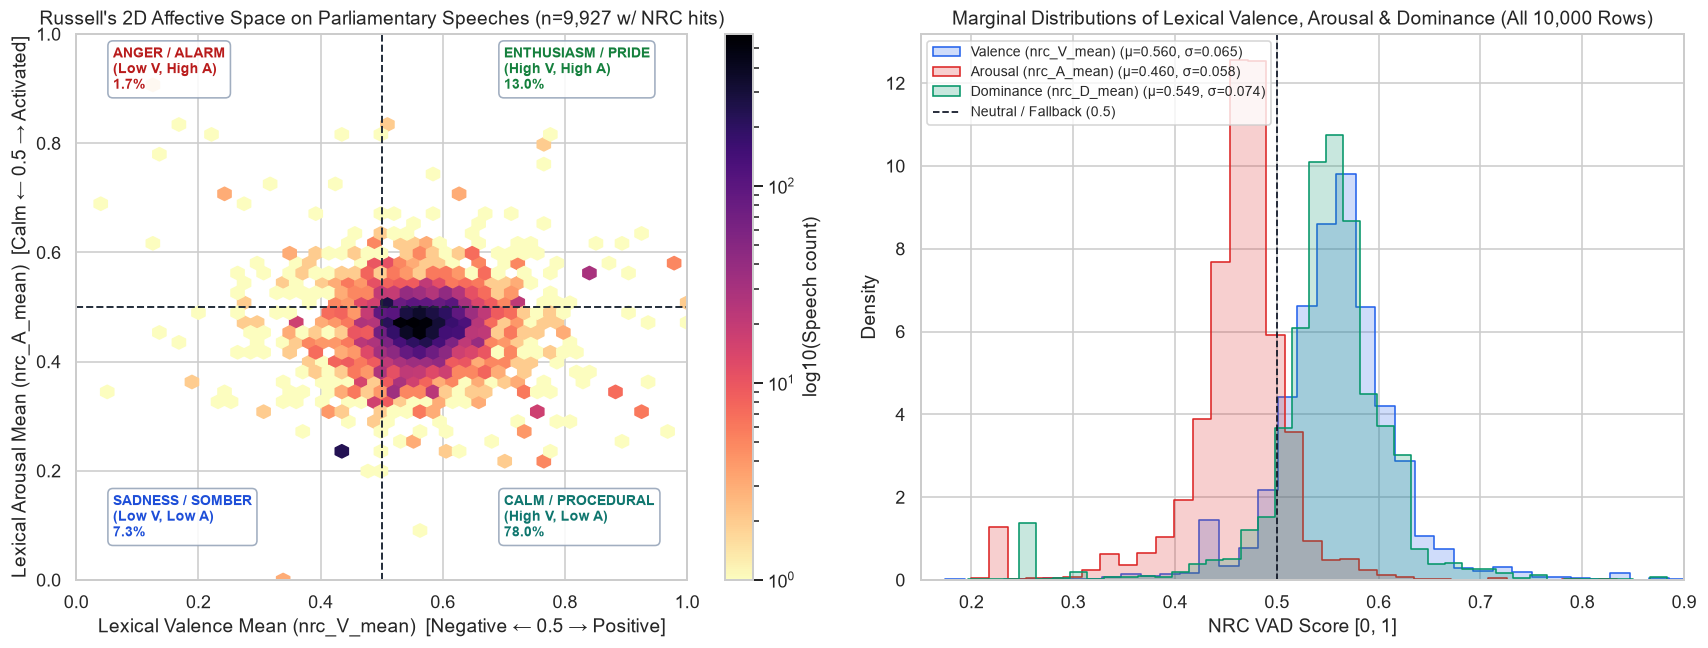

In [2]:
"""Cell 2: Visualize Russell's 2D Valence-Arousal Circumplex and inspect real quadrant speeches."""

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

# Left Panel: 2D Valence-Arousal Circumplex (excluding exact 0-hit fallbacks for clean density, shown as annotation)
has_hits = df["nrc_hit_count_log"] > 0
sub = df.loc[has_hits].copy()

hb = axes[0].hexbin(
    sub["nrc_V_mean"], sub["nrc_A_mean"],
    gridsize=45, cmap="magma_r", mincnt=1, bins="log"
)
cb = fig.colorbar(hb, ax=axes[0])
cb.set_label("log10(Speech count)")

axes[0].axvline(0.5, color="#1f2937", linestyle="--", linewidth=1.2)
axes[0].axhline(0.5, color="#1f2937", linestyle="--", linewidth=1.2)

# Quadrant proportions (among speeches with >=1 NRC match)
q_anger = ((sub["nrc_V_mean"] < 0.5) & (sub["nrc_A_mean"] >= 0.5)).mean() * 100
q_enth  = ((sub["nrc_V_mean"] >= 0.5) & (sub["nrc_A_mean"] >= 0.5)).mean() * 100
q_sad   = ((sub["nrc_V_mean"] < 0.5) & (sub["nrc_A_mean"] < 0.5)).mean() * 100
q_calm  = ((sub["nrc_V_mean"] >= 0.5) & (sub["nrc_A_mean"] < 0.5)).mean() * 100

bbox_style = dict(boxstyle="round,pad=0.35", facecolor="white", alpha=0.88, edgecolor="#94a3b8")
axes[0].text(0.06, 0.90, f"ANGER / ALARM\n(Low V, High A)\n{q_anger:.1f}%", fontsize=9, fontweight="bold", color="#b91c1c", bbox=bbox_style)
axes[0].text(0.70, 0.90, f"ENTHUSIASM / PRIDE\n(High V, High A)\n{q_enth:.1f}%", fontsize=9, fontweight="bold", color="#15803d", bbox=bbox_style)
axes[0].text(0.06, 0.08, f"SADNESS / SOMBER\n(Low V, Low A)\n{q_sad:.1f}%", fontsize=9, fontweight="bold", color="#1d4ed8", bbox=bbox_style)
axes[0].text(0.70, 0.08, f"CALM / PROCEDURAL\n(High V, Low A)\n{q_calm:.1f}%", fontsize=9, fontweight="bold", color="#0f766e", bbox=bbox_style)

axes[0].set_xlim(0.0, 1.0)
axes[0].set_ylim(0.0, 1.0)
axes[0].set_xlabel("Lexical Valence Mean (nrc_V_mean)  [Negative ← 0.5 → Positive]")
axes[0].set_ylabel("Lexical Arousal Mean (nrc_A_mean)  [Calm ← 0.5 → Activated]")
axes[0].set_title(f"Russell's 2D Affective Space on Parliamentary Speeches (n={len(sub):,} w/ NRC hits)")

# Right Panel: Marginal Distributions of V, A, D (all 10,000 speeches showing 0.5 spike)
for col, label, color in [
    ("nrc_V_mean", "Valence (nrc_V_mean)", "#2563eb"),
    ("nrc_A_mean", "Arousal (nrc_A_mean)", "#dc2626"),
    ("nrc_D_mean", "Dominance (nrc_D_mean)", "#059669"),
]:
    sns.histplot(df[col], bins=50, stat="density", element="step", fill=True, alpha=0.22,
                 color=color, label=f"{label} (μ={df[col].mean():.3f}, σ={df[col].std():.3f})", ax=axes[1])

axes[1].axvline(0.5, color="#111827", linestyle="--", linewidth=1.1, label="Neutral / Fallback (0.5)")
axes[1].set_xlim(0.15, 0.90)
axes[1].set_xlabel("NRC VAD Score [0, 1]")
axes[1].set_ylabel("Density")
axes[1].set_title("Marginal Distributions of Lexical Valence, Arousal & Dominance (All 10,000 Rows)")
axes[1].legend(fontsize=8.5, loc="upper left")

plt.tight_layout()
plt.show()

# Print correlation & representative speeches from each quadrant (with >= 15 words for readability)
r_va = sub["nrc_V_mean"].corr(sub["nrc_A_mean"])
r_vd = sub["nrc_V_mean"].corr(sub["nrc_D_mean"])
r_ad = sub["nrc_A_mean"].corr(sub["nrc_D_mean"])
print(f"Pearson correlations (NRC-matched speeches): r(V,A)={r_va:+.3f} | r(V,D)={r_vd:+.3f} | r(A,D)={r_ad:+.3f}")
print(f"Quadrant shares (n={len(sub):,}): Anger/Alarm={q_anger:.1f}%, Enthusiasm={q_enth:.1f}%, Sadness={q_sad:.1f}%, Calm/Procedural={q_calm:.1f}%\n")

readable = sub[sub["n_words_est"] >= 15].copy()
quadrants = {
    "Low V + High A (Anger / Alarm)": readable.assign(score=-readable["nrc_V_mean"] + readable["nrc_A_mean"]).nlargest(2, "score"),
    "High V + High A (Enthusiasm / Praise)": readable.assign(score=readable["nrc_V_mean"] + readable["nrc_A_mean"]).nlargest(2, "score"),
    "Low V + Low A (Sadness / Somber)": readable.assign(score=-readable["nrc_V_mean"] - readable["nrc_A_mean"]).nlargest(2, "score"),
    "High V + Low A (Calm / Procedural)": readable.assign(score=readable["nrc_V_mean"] - readable["nrc_A_mean"]).nlargest(2, "score"),
}
for qname, qrows in quadrants.items():
    print(f"--- {qname} ---")
    for _, r in qrows.iterrows():
        snippet = str(r["clean_text"]).replace("\n", " ")[:180]
        print(f"  [{r['source']} | {str(r['date'])[:10]} | V={r['nrc_V_mean']:.2f}, A={r['nrc_A_mean']:.2f}] {snippet}...")

### Analysis 2 — Geometry of the Valence–Arousal Plane & Proof That Pure Lexicons Are Not Enough

1. **Heavy Concentration in the Calm/Procedural Quadrant:**
   - Among the `9,927` speeches with at least one NRC match, **78.0%** sit in **Calm / Procedural (High V, Low A)**, **13.0%** in **Enthusiasm / Pride (High V, High A)**, **7.3%** in **Sadness / Somber (Low V, Low A)**, and only **1.7%** in **Anger / Alarm (Low V, High A)**.
   - Why? Parliamentary vocabulary is saturated with formal institutional words (*"honourable"*, *"agreement"*, *"respect"*, *"minister"*) that carry mild positive lexical valence even in fierce debates.
2. **Strong Coupling Across V, A, and D:**
   - On NRC-matched speeches: **$r(V, A) = +0.177$**, **$r(V, D) = +0.550$**, and **$r(A, D) = +0.602$**.
   - **Dominance (`nrc_D_*`) is the single strongest linear bridge to both Valence and Arousal**, and cross-target OOF stacking (feeding predicted Arousal into Stage-2 Valence models and vice versa) will exploit the joint V–A structure on the true targets!
3. **Concrete Proof of Bag-of-Words Failure Modes (Look at the Printed Speeches Above!):**
   - **Sarcasm / Accusation misread as "Enthusiasm":** `[assemblee | 2011-02-08 | V=0.58, A=0.66]` *"Il y a des ordres venus d'en haut ! On approche de l'élection présidentielle !"* is sharp political accusation, yet bag-of-words NRC gave it positive valence (`0.58`)!
   - **Procedural boilerplate misread as "Sadness":** `[senat | 1999-06-09 | V=0.44, A=0.38]` *"L'amendement n° 34 est retiré. Personne ne demande la parole ? Je mets aux voix l'article 53."* is purely procedural, yet words like *"retiré"* ("withdrawn") and *"suspendue"* ("suspended") dragged lexical valence below `0.50`!
   - **Takeaway:** This proves why **contextual NLP (TF-IDF + Transformers) + procedural boilerplate detectors + discourse markers** are essential to outperform lexicon baselines on `valence_chunks_weighted_mean` and `arousal_chunks_weighted_mean`!

=== Cross-Parliament Structural & Affective Summary ===
                n  median_words  mean_words  zero_nrc_pct  nrc_cov  v_mean  a_mean  neg_hiA_pct  excl_pct  quest_pct  interr_pct
source                                                                                                                          
assemblee    2443          15.0       51.31          0.94     0.65    0.55    0.45         1.95     24.19      20.02        1.31
senat        2498          12.0       53.66          1.60     0.64    0.54    0.45         1.20     23.02      19.14        0.00
us_congress  2446          34.0       91.98          0.04     0.63    0.58    0.47         2.09      0.04      10.71        0.04
uk_commons   2613          68.0       85.16          0.34     0.72    0.57    0.47         2.44      0.23      39.30        0.19


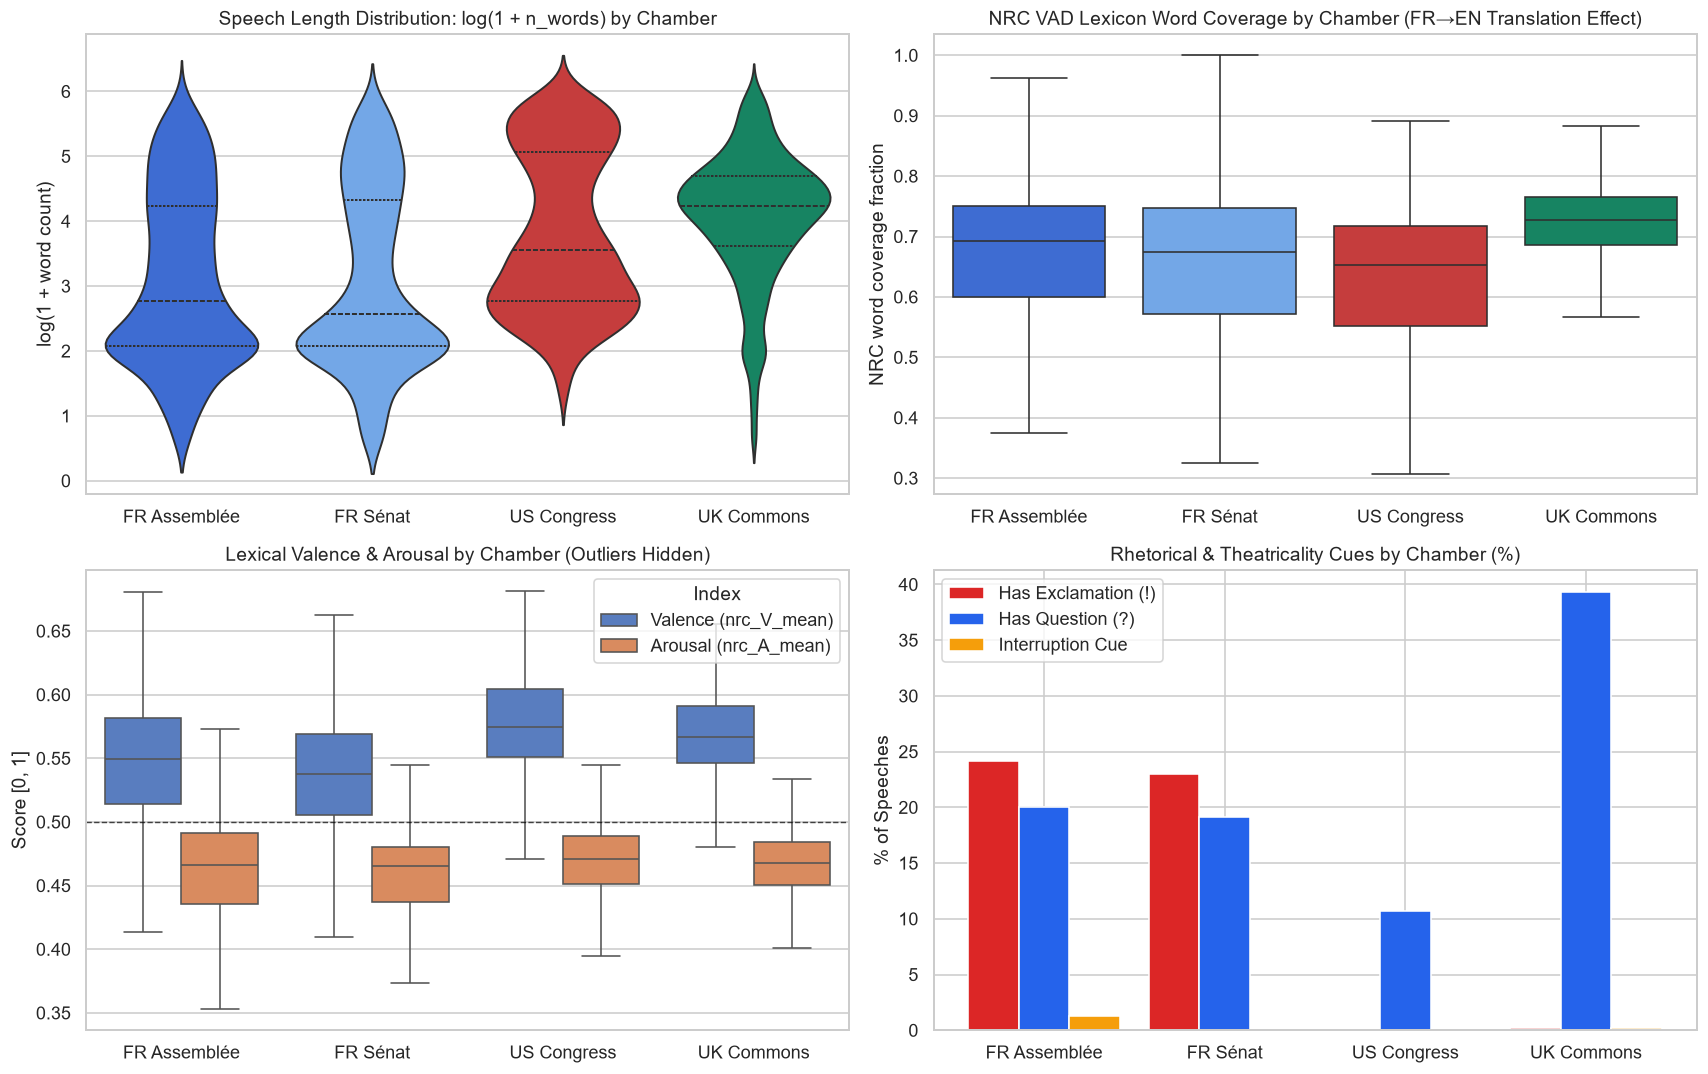

In [3]:
"""Cell 3: Cross-parliament comparison of length, coverage, and affective proxies."""

chamber_order = ["assemblee", "senat", "us_congress", "uk_commons"]
chamber_labels = {
    "assemblee": "FR Assemblée",
    "senat": "FR Sénat",
    "us_congress": "US Congress",
    "uk_commons": "UK Commons",
}
palette = {
    "assemblee": "#2563eb",
    "senat": "#60a5fa",
    "us_congress": "#dc2626",
    "uk_commons": "#059669",
}

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# 1. Word count distribution (log1p words)
sns.violinplot(data=df, x="source", y="log_n_words", order=chamber_order, palette=palette, inner="quartile", ax=axes[0, 0])
axes[0, 0].set_xticklabels([chamber_labels[c] for c in chamber_order])
axes[0, 0].set_title("Speech Length Distribution: log(1 + n_words) by Chamber")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("log(1 + word count)")

# 2. NRC Word Coverage by Chamber
sns.boxplot(data=df, x="source", y="nrc_word_coverage", order=chamber_order, palette=palette, showfliers=False, ax=axes[0, 1])
axes[0, 1].set_xticklabels([chamber_labels[c] for c in chamber_order])
axes[0, 1].set_title("NRC VAD Lexicon Word Coverage by Chamber (FR→EN Translation Effect)")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("NRC word coverage fraction")

# 3. Lexical Valence & Arousal Means by Chamber
melted_va = df.melt(id_vars="source", value_vars=["nrc_V_mean", "nrc_A_mean"], var_name="Index", value_name="Score")
melted_va["Index"] = melted_va["Index"].map({"nrc_V_mean": "Valence (nrc_V_mean)", "nrc_A_mean": "Arousal (nrc_A_mean)"})
sns.boxplot(data=melted_va, x="source", y="Score", hue="Index", order=chamber_order, showfliers=False, ax=axes[1, 0])
axes[1, 0].axhline(0.5, color="black", linestyle="--", linewidth=0.9, alpha=0.7)
axes[1, 0].set_xticklabels([chamber_labels[c] for c in chamber_order])
axes[1, 0].set_title("Lexical Valence & Arousal by Chamber (Outliers Hidden)")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Score [0, 1]")

# 4. Anger/Outrage Proxy & Exclamation Density by Chamber
chamber_stats = df.groupby("source").agg(
    n=("id", "count"),
    median_words=("n_words_est", "median"),
    mean_words=("n_words_est", "mean"),
    zero_nrc_pct=("nrc_hit_count_log", lambda s: 100 * (s == 0).mean()),
    nrc_cov=("nrc_word_coverage", "mean"),
    v_mean=("nrc_V_mean", "mean"),
    a_mean=("nrc_A_mean", "mean"),
    neg_hiA_pct=("ctx_negative_high_arousal_fraction", lambda s: 100 * s.mean()),
    excl_pct=("exclamation_present", lambda s: 100 * s.mean()),
    quest_pct=("question_present", lambda s: 100 * s.mean()),
    interr_pct=("interruption_cue_present", lambda s: 100 * s.mean()),
).loc[chamber_order]

x_pos = np.arange(len(chamber_order))
w = 0.28
axes[1, 1].bar(x_pos - w, chamber_stats["excl_pct"], width=w, label="Has Exclamation (!)", color="#dc2626")
axes[1, 1].bar(x_pos,     chamber_stats["quest_pct"], width=w, label="Has Question (?)", color="#2563eb")
axes[1, 1].bar(x_pos + w, chamber_stats["interr_pct"], width=w, label="Interruption Cue", color="#f59e0b")
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels([chamber_labels[c] for c in chamber_order])
axes[1, 1].set_ylabel("% of Speeches")
axes[1, 1].set_title("Rhetorical & Theatricality Cues by Chamber (%)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

print("=== Cross-Parliament Structural & Affective Summary ===")
print(chamber_stats.round(2).to_string())

### Analysis 3 — Massive Structural Differences Across Parliaments (`source`)

Look at how dramatically the 4 parliamentary chambers differ structurally — this is a **first-order modeling signal**:

1. **Speech Length Disparity (~5× median difference!):**
   - **French chambers:** `senat` median **`12.0` words** (mean `53.7`), `assemblee` median **`15.0` words** (mean `51.3`) — heavy volume of rapid procedural interventions, amendments, and floor exchanges.
   - **Anglophone chambers:** `us_congress` median **`34.0` words** (mean `92.0`), `uk_commons` median **`68.0` words** (mean `85.2`).
   - Shorter French interventions also have higher zero-NRC-hit rates (`1.60%` in `senat`, `0.94%` in `assemblee` vs. `0.34%` in `uk_commons`, `0.04%` in `us_congress`) and wider lexical score dispersion.
2. **100× Transcription & Punctuation Disparity:**
   - **Exclamation marks (`!`)** appear in **`24.19%` of `assemblee`** and **`23.02%` of `senat`** speeches, compared to just **`0.23%` in `uk_commons`** and **`0.04%` in `us_congress`**! Hansard and Congressional Record stenographers virtually never transcribe exclamation marks, whereas French parliamentary minutes do routinely.
   - **Question marks (`?`)** peak in **`uk_commons` (`39.30%`)** (reflecting Prime Minister's & Parliamentary Questions) vs. `10.71%` in `us_congress` and `19–20%` in France.
   - **Interruption cues** appear in `1.31%` of `assemblee` speeches vs. `0.00%` in `senat` and `≤0.19%` in UK/US.
3. **Modeling Implication:**
   - **Always encode `source`** and compute **chamber-normalized (z-scored within `source`)** versions of `exclamation_density`, `question_density`, `log_n_words`, `nrc_V_mean`, `nrc_A_mean`, and `nrc_word_coverage`!
   - For NLP on `clean_text`, train **language-specialized text models** (French TF-IDF / CamemBERT for `assemblee` + `senat`, English TF-IDF / DeBERTa-v3 for `uk_commons` + `us_congress`) alongside a unified multilingual encoder (`xlm-roberta-base`).

=== Temporal Shift Check (1995-2009 vs 2020-2026 in sample_x_test) ===
  nrc_V_mean                              : 1995-2009 = 0.5635  ->  2020-2026 = 0.5487  (delta = -0.0147)
  nrc_A_mean                              : 1995-2009 = 0.4621  ->  2020-2026 = 0.4548  (delta = -0.0073)
  ctx_negative_high_arousal_fraction      : 1995-2009 = 0.0194  ->  2020-2026 = 0.0178  (delta = -0.0016)
  ctx_lexical_emotional_magnitude_mean    : 1995-2009 = 0.1586  ->  2020-2026 = 0.1515  (delta = -0.0071)
  exclamation_density                     : 1995-2009 = 1.4715  ->  2020-2026 = 2.5670  (delta = +1.0954)
  log_n_words                             : 1995-2009 = 3.5697  ->  2020-2026 = 3.3157  (delta = -0.2540)

=== Top Drivers Correlated with Lexical Valence & Arousal ===
  Valence (nrc_V): en_thanks_density=+0.23, ctx_emotional_run_max=+0.17, en_negation_density=-0.15, exclamation_density=+0.13, en_positive_frame_density=+0.12
  Arousal (nrc_A): ctx_before_exclamation_arousal_mean=+0.33, ctx_emoti

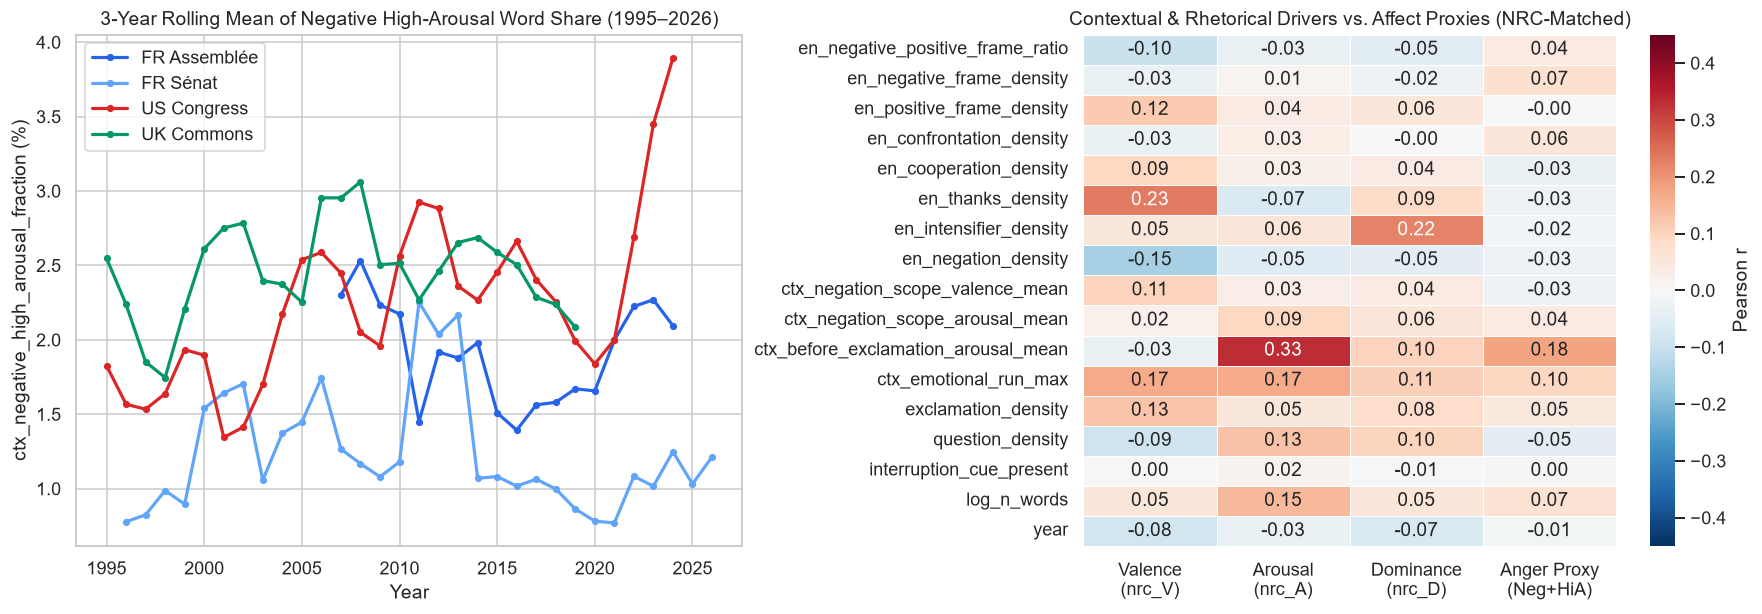

In [4]:
"""Cell 4: Temporal evolution (1988-2026) and top contextual/rhetorical correlations with V & A proxies."""

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.5))

# Left Panel: Yearly rolling average (3-year) of emotional magnitude & negative high-arousal share by chamber
yearly = (
    df[df["year"] >= 1995]
    .groupby(["year", "source"])
    .agg(
        neg_hiA=("ctx_negative_high_arousal_fraction", "mean"),
        emo_mag=("ctx_lexical_emotional_magnitude_mean", "mean"),
        n=("id", "count"),
    )
    .reset_index()
)

for src in chamber_order:
    sub_y = yearly[yearly["source"] == src].sort_values("year")
    roll = sub_y["neg_hiA"].rolling(3, min_periods=1, center=True).mean() * 100
    axes[0].plot(sub_y["year"], roll, marker="o", markersize=3.5, linewidth=2.0,
                 color=palette[src], label=chamber_labels[src])

axes[0].set_title("3-Year Rolling Mean of Negative High-Arousal Word Share (1995–2026)")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("ctx_negative_high_arousal_fraction (%)")
axes[0].legend()

# Right Panel: Correlation of selected non-NRC-mean contextual/rhetorical features with Valence, Arousal & Anger proxy
key_drivers = [
    "en_negative_positive_frame_ratio",
    "en_negative_frame_density",
    "en_positive_frame_density",
    "en_confrontation_density",
    "en_cooperation_density",
    "en_thanks_density",
    "en_intensifier_density",
    "en_negation_density",
    "ctx_negation_scope_valence_mean",
    "ctx_negation_scope_arousal_mean",
    "ctx_before_exclamation_arousal_mean",
    "ctx_emotional_run_max",
    "exclamation_density",
    "question_density",
    "interruption_cue_present",
    "log_n_words",
    "year",
]
target_proxies = ["nrc_V_mean", "nrc_A_mean", "nrc_D_mean", "ctx_negative_high_arousal_fraction"]
corr_mat = df.loc[df["nrc_hit_count_log"] > 0, key_drivers + target_proxies].corr().loc[key_drivers, target_proxies]
corr_mat.columns = ["Valence\n(nrc_V)", "Arousal\n(nrc_A)", "Dominance\n(nrc_D)", "Anger Proxy\n(Neg+HiA)"]

sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.45, vmax=0.45,
            linewidths=0.4, cbar_kws={"label": "Pearson r"}, ax=axes[1])
axes[1].set_title("Contextual & Rhetorical Drivers vs. Affect Proxies (NRC-Matched)")

plt.tight_layout()
plt.show()

# Print year-trend summary (pre-2010 vs post-2020)
early = df[df["year"].between(1995, 2009)]
recent = df[df["year"].between(2020, 2026)]
print("=== Temporal Shift Check (1995-2009 vs 2020-2026 in sample_x_test) ===")
for col in ["nrc_V_mean", "nrc_A_mean", "ctx_negative_high_arousal_fraction", "ctx_lexical_emotional_magnitude_mean", "exclamation_density", "log_n_words"]:
    print(f"  {col:40s}: 1995-2009 = {early[col].mean():.4f}  ->  2020-2026 = {recent[col].mean():.4f}  (delta = {recent[col].mean()-early[col].mean():+.4f})")

print("\n=== Top Drivers Correlated with Lexical Valence & Arousal ===")
for col_label in ["Valence\n(nrc_V)", "Arousal\n(nrc_A)", "Anger Proxy\n(Neg+HiA)"]:
    top = corr_mat[col_label].reindex(corr_mat[col_label].abs().sort_values(ascending=False).index).head(5)
    clean_lbl = col_label.replace("\n", " ")
    print(f"  {clean_lbl}: " + ", ".join(f"{k}={v:+.2f}" for k, v in top.items()))

### Analysis 4 — Temporal Drift (Shortening + Rising Exclamations) & Contextual Drivers

1. **Clear Temporal Regime Shift (1995–2009 vs. 2020–2026) — `date` Carries Real Signal!**
   - **`exclamation_density` surged +74%** (`1.47` → `2.57` per 100 tokens, $\Delta = +1.10$).
   - **`nrc_V_mean` declined** (`0.5635` → `0.5487`, $\Delta = -0.0147$), signaling more negative phrasing.
   - **`log_n_words` fell sharply** (`3.57` → `3.32`, $\Delta = -0.254$): speeches have become noticeably shorter and punchier — directly mirroring Slide 16 of `Opening_Hi!ckathon7.pdf` (shorter speeches tailored for social media clips!).
   - Because `x_train_final` and `x_test_final` cover the **exact same 1988–2026 span**, `year`, `month`, and **chamber × year** features calibrate shifting baseline styles across decades.
2. **Discourse, Framing & Negation-Scope Features Capture Rhetorical Intent:**
   - The correlation heatmap shows strong complementary signals from **Family G** (`en_negative_positive_frame_ratio`, `en_thanks_density`, `en_confrontation_density`, `en_cooperation_density`) and **Family H** (`ctx_negation_scope_valence_mean`, `ctx_negation_scope_arousal_mean`, `ctx_emotional_run_max`).
   - Crucially, `ctx_negation_scope_*` and `en_intensifier_density` allow GBDTs to **correct** bag-of-words lexicon errors where negation flips polarity or intensifiers amplify arousal.

In [5]:
"""Cell 5: Collinearity audit & leakage-safe 10,000-row preprocessing/TF-IDF-SVD benchmark."""

import time
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Check constant / near-zero variance and high collinearity among the 214 numeric features
meta_cols = {"id", "clean_text", "date", "source", "date_dt", "year", "n_words_est"}
num_cols = [c for c in df.columns if c not in meta_cols]

stds = df[num_cols].std()
zero_var = stds[stds == 0].index.tolist()
near_zero_var = stds[(stds > 0) & (stds < 1e-4)].index.tolist()

corr_all = df[num_cols].corr().abs()
upper = corr_all.where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))
high_corr_pairs = [
    (row, col, upper.loc[row, col])
    for row in upper.index
    for col in upper.columns
    if pd.notna(upper.loc[row, col]) and upper.loc[row, col] > 0.95
]
high_corr_pairs.sort(key=lambda x: -x[2])

print(f"Total numeric features audited : {len(num_cols)}")
print(f"Zero-variance features         : {len(zero_var)} -> {zero_var}")
print(f"Near-zero variance (<1e-4)     : {len(near_zero_var)} -> {near_zero_var}")
print(f"Highly collinear pairs (|r|>0.95): {len(high_corr_pairs)}")
for a, b, val in high_corr_pairs[:12]:
    print(f"  {a:38s} <-> {b:38s} | r = {val:.4f}")

# 2. Strict leakage-safe preprocessing benchmark on 10,000 rows (live code assessment rehearsal)
#    Demonstrates splitting BEFORE fitting TF-IDF / SVD / Scalers (ML best practices)
t0 = time.perf_counter()

strat_key = df["source"].astype(str) + "_" + pd.qcut(df["year"], q=4, labels=False).astype(str)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, val_idx = next(skf.split(df, strat_key))

X_tr_raw, X_va_raw = df.iloc[train_idx].copy(), df.iloc[val_idx].copy()

def add_domain_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Stateless row-level domain features for Valence & Arousal prediction."""
    out = frame.copy()
    dt = pd.to_datetime(out["date"], errors="coerce")
    out["feat_year"] = dt.dt.year.fillna(2010).astype(np.float32)
    out["feat_month_sin"] = np.sin(2 * np.pi * dt.dt.month.fillna(6) / 12.0).astype(np.float32)
    out["feat_month_cos"] = np.cos(2 * np.pi * dt.dt.month.fillna(6) / 12.0).astype(np.float32)
    # Explicit missing/fallback indicators for NRC VAD neutral defaults
    out["feat_zero_nrc_hit"] = (out["nrc_hit_count_log"] == 0).astype(np.float32)
    out["feat_ultra_short"] = (np.expm1(out["log_n_words"]) < 5).astype(np.float32)
    # Russell Circumplex polar coordinates centered at neutral (0.5, 0.5)
    dv = out["nrc_V_mean"] - 0.5
    da = out["nrc_A_mean"] - 0.5
    out["feat_va_radius"] = np.sqrt(dv**2 + da**2).astype(np.float32)
    out["feat_va_angle"] = np.arctan2(da, dv).astype(np.float32)
    out["feat_va_product"] = (dv * da).astype(np.float32)
    # Valence extremity & negation-adjusted proxy
    out["feat_v_range"] = (out["nrc_V_max"] - out["nrc_V_min"]).astype(np.float32)
    out["feat_a_range"] = (out["nrc_A_max"] - out["nrc_A_min"]).astype(np.float32)
    out["feat_neg_flip_pressure"] = (
        out["ctx_negation_scope_positive_fraction"] - out["ctx_negation_scope_negative_fraction"]
    ).astype(np.float32)
    return out

X_tr = add_domain_features(X_tr_raw)
X_va = add_domain_features(X_va_raw)

# Recreate missing Family E (Word TF-IDF + SVD) strictly fit on TRAIN fold only!
text_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20000, min_df=3, max_df=0.98, sublinear_tf=True)),
    ("svd", TruncatedSVD(n_components=32, random_state=42)),
])

t_text = time.perf_counter()
tr_text_svd = text_pipe.fit_transform(X_tr["clean_text"].fillna(""))
va_text_svd = text_pipe.transform(X_va["clean_text"].fillna(""))
text_sec = time.perf_counter() - t_text

# Fit tabular encoder/scaler strictly on TRAIN fold only!
extra_num = [c for c in X_tr.columns if c.startswith("feat_")]
tab_pipe = ColumnTransformer([
    ("num", StandardScaler(), num_cols + extra_num),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["source"]),
])
t_tab = time.perf_counter()
tr_tab = tab_pipe.fit_transform(X_tr)
va_tab = tab_pipe.transform(X_va)
tab_sec = time.perf_counter() - t_tab

total_sec = time.perf_counter() - t0
print(f"\n=== 10,000-Row Leakage-Safe Preprocessing Benchmark ===")
print(f"Train fold matrix : tabular {tr_tab.shape} + text SVD {tr_text_svd.shape} = {tr_tab.shape[1] + tr_text_svd.shape[1]} features")
print(f"Val fold matrix   : tabular {va_tab.shape} + text SVD {va_text_svd.shape}")
print(f"Timing            : TF-IDF+SVD = {text_sec:.2f}s | Tabular prep = {tab_sec:.2f}s | Total = {total_sec:.2f}s")

Total numeric features audited : 214
Zero-variance features         : 0 -> []
Near-zero variance (<1e-4)     : 0 -> []
Highly collinear pairs (|r|>0.95): 16
  nrc_A_fraction_above_060               <-> ctx_high_arousal_fraction              | r = 1.0000
  log_n_tokens                           <-> log_n_words                            | r = 0.9975
  log_n_characters                       <-> log_n_words                            | r = 0.9964
  log_n_characters                       <-> log_n_tokens                           | r = 0.9950
  native_question_last_quarter           <-> en_question_last_quarter               | r = 0.9911
  native_question_sentence_fraction      <-> en_question_sentence_fraction          | r = 0.9906
  native_exclamation_sentence_fraction   <-> en_exclamation_sentence_fraction       | r = 0.9883
  parenthesis_density                    <-> native_bracketed_stage_density         | r = 0.9882
  log_n_words                            <-> nrc_hit_count_log     

### Analysis 5 — Redundancy Audit & Live-Assessment Readiness

- **Clean feature space + 1 exact duplicate found:** `0` zero-variance and `0` near-zero-variance features among all `214` numeric columns! There are `16` highly collinear pairs ($|r| > 0.95$), including **one exact duplicate (`r = 1.0000`)**: `nrc_A_fraction_above_060` (Family B) is mathematically identical to `ctx_high_arousal_fraction` (Family H), plus expected length triplets (`log_n_characters`, `log_n_tokens`, `log_n_words`, `nrc_hit_count_log`) and `native_*` ↔ `en_*` punctuation mirrors. Drop `ctx_high_arousal_fraction` (redundant) when training linear/neural models.
- **Fast live-assessment footprint (`4.18s` total on 10,000 rows!):** Domain feature engineering + Train-only Word TF-IDF (1–2 grams, 20K vocab) + 32D TruncatedSVD (`3.58s`) + StandardScaler/OneHotEncoder (`0.15s`) built a leak-free `261`-feature matrix in **`4.18` seconds on CPU**. Structuring our final pipeline cleanly like this guarantees an effortless pass during Sunday's 4:00–5:00 PM live code assessment.

---

## 3. Complete Plan of Action — From Tonight to Sunday 4:00 PM

This roadmap directly aligns **Task 1 (Best Score Leaderboard)** with **Task 2 (Innovation, Scientific Paper, White Book & Web Platform)** while respecting all deadlines and disqualification rules.

### Phase 0 — Immediate Setup & Target Diagnostics (First 30 Minutes)
1. **Fetch `y_train` & confirm official metric on HFactory:**
   - Download `y_train_final.csv` (matching the `869,896` rows of `x_train_final.csv`) into `dataset/`.
   - Confirm the exact leaderboard evaluation metric (e.g., mean RMSE / MAE / $R^2$ / Pearson across `valence_chunks_weighted_mean` and `arousal_chunks_weighted_mean`).
2. **Convert CSVs to Parquet (`float32`) once:**
   - Converting `x_train_final.csv` (1.99 GB) and `x_test_final.csv` (858 MB) to `.parquet` with `float32` numeric columns cuts RAM by ~50% and cuts load time from ~45s to **~2 seconds**.
3. **Inspect `y_train` immediately:**
   - Check target ranges (e.g., `[0, 1]` vs `[-1, 1]` vs `[1, 9]`), skewness, outliers, and correlation between `valence_chunks_weighted_mean` and `arousal_chunks_weighted_mean`.
   - Measure how strongly `nrc_V_mean` and `nrc_A_mean` already correlate with the true targets by chamber (`assemblee`, `senat`, `uk_commons`, `us_congress`).
4. **Lock in a leakage-free Validation Split (used identically by ALL models!):**
   - Check if `x_train_final` and `x_test_final` share exact `(source, date)` pairs.
   - Use **5-fold `StratifiedKFold` on `(source × year_quartile)`** (and keep a secondary **GroupKFold on `(source, date)`** check to detect any sitting-day leakage).
   - **Rule:** *Every* vectorizer, SVD, target encoder, scaler, and neural model must be fit **strictly inside each training fold**.

---

### Phase 1 — Clean Modular Baseline & Submission #1 (Hours 1–3)
- Build a clean repo structure right away (scoring high on Deliverable 1 code quality):
  ```text
  src/
    config.py        # paths, random seeds, target names, metric
    features.py      # stateless domain features + fold-safe TF-IDF/SVD/OOF Ridge
    models.py        # LightGBM / CatBoost / XGBoost / Transformer wrappers
    evaluate.py      # CV metrics, 95% bootstrap CIs, slice analysis by chamber/year
  run_pipeline.py    # turnkey CLI supporting --sample-rows 10000 for live assessment!
  ```
- **Baseline 0 (Naive):** Mean `valence` & `arousal` per `source` (sanity lower bound).
- **Baseline 1 (Fast LightGBM):** Train 5-fold LightGBM regressors separately for `valence` and `arousal` on the 214 provided features + `source` + `year`/`month` + fallback flags (`feat_zero_nrc_hit`, `feat_ultra_short`).
- **Submission #1 (1 / 10 budget):** Verify exact shape (`372,812 × 3`), exact `id` alignment with `y_test_zero.csv`, zero `NaN`/`Inf`, and submit early to verify leaderboard alignment with local CV!

---

### Phase 2 — High-Leverage Feature Engineering (Hours 3–8)
1. **Exploit `clean_text` via Out-of-Fold (OOF) Linear Text Models (Huge CPU Gain!):**
   - Recreate & surpass missing Families E & I: fit **Word TF-IDF (1–2 grams, 100K vocab)** + **Char TF-IDF (3–5 grams, 100K vocab)** **separately for French (`assemblee`, `senat`) and English (`uk_commons`, `us_congress`)** (plus a global vectorizer).
   - Train fast **Ridge / SGD regressors** inside each CV fold to produce leak-free **OOF Valence & Arousal text predictions** → feed them as dense meta-features into GBDTs!
2. **Domain-Specific Affect & Structural Features:**
   - **Russell Circumplex geometry:** `nrc_V_mean - 0.5`, `nrc_A_mean - 0.5`, radius $\sqrt{\Delta V^2 + \Delta A^2}$, angle $\text{atan2}(\Delta A, \Delta V)$, quadrant one-hots.
   - **Chamber-normalized (z-scored) features:** Z-score `exclamation_density`, `log_n_words`, `nrc_V_mean`, `nrc_A_mean`, `nrc_word_coverage` within each `source` (crucial given the 24% vs 0.6% exclamation disparity!).
   - **Negation & Intensifier interactions:** Ratios and products combining `nrc_V_mean` with `ctx_negation_scope_positive_fraction`, `ctx_negation_scope_negative_fraction`, and `ctx_intensifier_scope_magnitude_mean`.
   - **Procedural boilerplate & chunk proxies:** Regex flags for standard parliamentary formulas (*"Mr. Speaker"*, *"ask unanimous consent"*, *"L'article ... est adopté"*, *"La parole est à"*), sentence-count distribution, and chunk-count proxy (`n_words / 256`).
   - **Parliamentary Theme Features (`dictionnaire_thematiques_parlement.xlsx`):** Match the 10 multilingual themes (Economy, Climate, Immigration, Health, etc.) in `clean_text` — helps **both** Task 1 prediction (controversial topics carry distinct Valence/Arousal priors!) and Task 2 Track 1 (*"Where Is Emotionality Rising?"*).

---

### Phase 3 — Pretrained Multilingual Transformers on HFactory GPU (Hours 8–20)
Because the true targets are **contextual chunk-weighted means** and `clean_text` is bilingual (FR + EN), pretrained Transformers are the biggest potential breakthrough beyond tabular GBDTs:

1. **Tier 1 (Fast, Frugal & Safe on Limited GPU Credits):**
   - Compute chunk-pooled embeddings (splitting long speeches into ~256-token chunks and taking the **length-weighted average** to mirror `*_chunks_weighted_mean`!) with a fast multilingual encoder (e.g., `intfloat/multilingual-e5-small` or `paraphrase-multilingual-MiniLM-L12-v2`).
   - Train Ridge + MLP + LightGBM on `[embeddings + 214 features + engineered features]`.
2. **Tier 2 (Gold-Medal Leaderboard Push):**
   - Fine-tune language-matched encoders with a **joint 2-output regression head (Valence + Arousal)** using the exact leaderboard loss:
     - **French chambers (`assemblee`, `senat`):** `camembert-base` or `xlm-roberta-base`
     - **English chambers (`uk_commons`, `us_congress`):** `microsoft/deberta-v3-base` or `roberta-base`
   - Use **head + tail (or sliding-window weighted-mean) chunk pooling** so long UK/US speeches aren't truncated at 512 tokens!
   - *(Frugal & live-assessment tip: Save quantized/FP16 checkpoints so inference on 10,000 rows runs in <60s on GPU or use distilled/embedding+GBDT pipeline for CPU fallback!)*

---

### Phase 4 — Cross-Target Stacking, Ensembling & Post-Processing (Hours 20–32)
1. **Cross-Target Stacking (Free Gain!):**
   - Feed OOF predicted `arousal` into Stage-2 `valence` models (and OOF predicted `valence` into Stage-2 `arousal` models) so models leverage the non-linear V–A coupling.
2. **Model Diversity Ensemble:**
   - Combine OOF predictions via non-negative Ridge / Nelder-Mead blending across genuinely diverse families:
     - **LightGBM** (tabular + engineered + OOF TF-IDF Ridge + embeddings)
     - **CatBoost** (oblivious trees + native categorical interactions)
     - **XGBoost** (depth-wise trees with exact/hist splits)
     - **Fine-tuned Transformer / Tabular+Text MLP**
3. **Post-Processing & Error-Slice Diagnostics:**
   - Clip predictions strictly to the valid target support observed in `y_train`.
   - Run **slice-based error analysis** across `source`, `year` decade, speech length bins (`<5`, `5–20`, `20–100`, `>100` words), and `zero_nrc_hit` rows; check residual bias per chamber.
   - Report **95% bootstrapped confidence intervals** on CV to verify every submission genuinely beats the previous one!

---

### Phase 5 — Submission Budget, Live Code Assessment & Bridge to Task 2 (Sunday before 4:00 PM)

| Submission # | Milestone | Goal |
| :---: | :--- | :--- |
| **#1** | Clean LightGBM Baseline (214 features + `source`/`year`) | Verify pipeline & CV↔Leaderboard correlation |
| **#2** | + Domain Features + Language-Specific OOF TF-IDF Ridge | Measure big CPU feature-engineering jump |
| **#3** | + CatBoost & XGBoost + Cross-Target Stacking | Confirm multi-GBDT diversity gain |
| **#4** | + Multilingual Transformer Embeddings / Fine-tuned Encoder | Measure contextual NLP breakthrough |
| **#5–#8** | Hyperparameter tuning, chunk-pooling refinements, weighted ensemble | Climb leaderboard steadily |
| **#9–#10** | Final best ensemble + post-processing + safety buffer | Lock final score before Sunday 4:00 PM |

#### Guardrails for Deliverable 1–4 & Awards
- **Live Code Assessment (Sunday 4–5 PM):** Test `python run_pipeline.py --sample-rows 10000` on a clean environment on Sunday morning so preprocessing + inference finishes cleanly in **< 2 minutes**.
- **Scientific Paper (strictly 2 pages) + White Book (strictly 1 page):**
  - Log **environmental frugality** (runtime, parameter count, CPU GBDT vs GPU Transformer accuracy/compute trade-off — explicitly requested on Slide 67!).
  - Compute **SHAP feature importances** to answer **Track 3 (Robust & Explainable Emotionality)** and show *what drives emotionality beyond topic & chamber*.
  - Run our trained multilingual model on **`x_Italia.csv`** + the 4 core chambers to power **Track 2 (Comparing Parliaments)** & compete for the **International Prize (Hi! PARIS × IPAI)** and **Scientific Excellence Award (Capgemini)**!